## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [52]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Patrick Lee

**Date:** 10/21/2026

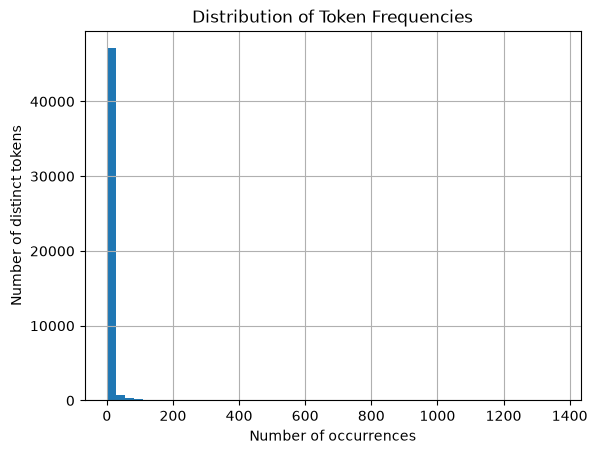

       token  occurrences
0        new         1365
1       date         1202
2        get         1052
3     please         1022
4      enron          927
5       like          923
6       2002          869
7      would          806
8        one          798
9    message          795
10      call          740
11      free          691
12  software          680
13      dear          651
14      know          644
count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
Name: occurrences, dtype: float64


In [53]:
# Your Phase 1 solution to the problem goes here.
# Q1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

frequencies = pd.DataFrame(token_freq, columns=["token", "occurrences"])
frequencies["occurrences"].hist(bins=50)
plt.xlabel("Number of occurrences")
plt.ylabel("Number of distinct tokens")
plt.title("Distribution of Token Frequencies")
plt.show()

print(frequencies.head(15))
print(frequencies["occurrences"].describe())

The token frequencies are right-skewed. Most tokens only appear once or twice, some appear more often. The median is 1 occurrence and the maximum is 1,365. This is probably why the histogram has one very tall bar on the left and a long tail to the right.

In [54]:
# Q2
from sklearn.model_selection import train_test_split

df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.loc[:, df.columns != "Email Type"]
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

In [55]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train, y_train)
train_rsq = model.score(X_train, y_train)
test_rsq = model.score(X_test, y_test)

print("Training R^2:", train_rsq)
print("Test R^2:", test_rsq)

Training R^2: 0.7680301260237321
Test R^2: 0.6587519780798339


In [56]:
coefficients = pd.DataFrame({
    "word": X_train.columns,
    "coefficient": model.coef_,
    "magnitude": np.sqrt(model.coef_ ** 2)
})

print(coefficients.sort_values("magnitude", ascending=False).head(15))

                   word  coefficient  magnitude
1504  background-image:    -0.891476   0.891476
740           localized     0.815698   0.815698
1406         helvetica,     0.717349   0.717349
2362            thermal     0.706216   0.706216
906               aging     0.622411   0.622411
2566         transcript     0.578132   0.578132
2559            april's    -0.546313   0.546313
1494         retrieving    -0.527824   0.527824
818                cnet    -0.510492   0.510492
2657              zdnet    -0.503465   0.503465
2532             xanaax     0.503086   0.503086
1256             arial,    -0.485267   0.485267
835        intervention    -0.450524   0.450524
1245  {text-decoration:     0.449816   0.449816
1839              form.     0.442778   0.442778


The training R^2 is 0.7680 and the test R^2 is 0.6588. The model performs better on the training data which could indicate some overfitting but it still explains a substantial amount of variation in the test outcomes.

The tokens with the largest coefficients in absolute value are “background-image:” (-0.8915), “localized” (0.8157), “helvetica,” (0.7173), and “thermal” (0.7062). The positive coefficients increase the predicted phishing score and the negative coefficient decreases it.

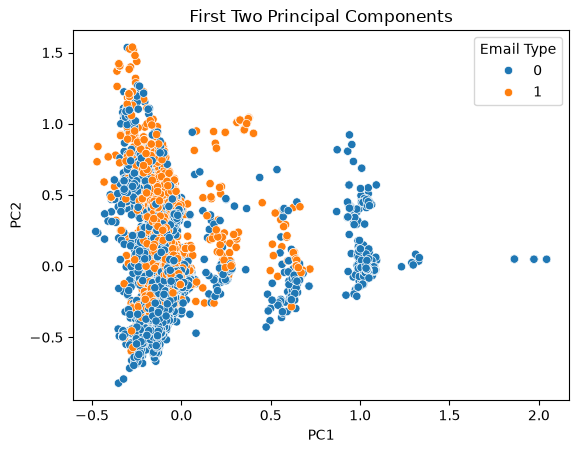

In [57]:
# Q3
import seaborn as sns
Z = X - X.mean()
C = (Z.T @ Z) / (len(Z) - 1)

eigenvalues, eigenvectors = np.linalg.eigh(C)

order = np.argsort(eigenvalues)[::-1]
eigenvectors = eigenvectors[:, order]

L = 2
P = eigenvectors[:, :L]
X_pca = Z @ P

plot_df = pd.DataFrame(
    X_pca.to_numpy(),
    columns=["PC1", "PC2"]
)
plot_df["Email Type"] = y.to_numpy()

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Email Type"
)
plt.title("First Two Principal Components")
plt.show()

The two classes overlap a lot, mostly in the large group around the left side. There are some smaller groups farther to the right. The one around PC1 = 1 is mostly not phishing and pretty large. Overall the first two components don't very clearly separate phishing from non-phishing emails.

In [58]:
# Q4
training_means = X_train.mean()

Z_train = X_train - training_means
Z_test = X_test - training_means

C_train = (Z_train.T @ Z_train) / (len(Z_train) - 1)

train_eigenvalues, train_eigenvectors = np.linalg.eigh(C_train)

train_order = np.argsort(train_eigenvalues)[::-1]
train_eigenvectors = train_eigenvectors[:, train_order]

L = 2610
P_train = train_eigenvectors[:, :L]

X_train_pca = Z_train @ P_train
X_test_pca = Z_test @ P_train

pca_model = LinearRegression().fit(X_train_pca, y_train)

pca_train_rsq = pca_model.score(X_train_pca, y_train)
pca_test_rsq = pca_model.score(X_test_pca, y_test)

print("Number of components:", X_train_pca.shape[1])
print("Original features — training R^2:", train_rsq)
print("PCA features — training R^2:", pca_train_rsq)
print("Original features — test R^2:", test_rsq)
print("PCA features — test R^2:", pca_test_rsq)
print("Change in test R^2:", pca_test_rsq - test_rsq)

Number of components: 2610
Original features — training R^2: 0.7680301260237321
PCA features — training R^2: 0.7673333826623745
Original features — test R^2: 0.6587519780798339
PCA features — test R^2: 0.6597095337755963
Change in test R^2: 0.000957555695762391


Using 2610 principal components gives a training R^2 of approximately 0.7673 and a test R^2 of approximately 0.6597. The original regression had a training R^2 of 0.7680 and a test R^2 of 0.6588. The PCA model fits the training data slightly worse but performs slightly better on the test data. I think the improvement is small so the two models perform similarly overall.

Q5

Principal components combine the original features into new and uncorrelated features. Keeping fewer components lets me run regression with fewer inputs while keeping a lot of the variation in the original data. This can reduce redundancy and make the regression more stable, even though it doesn't guarantee better predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 96cf2e0f75eb2629fd82da93b43f623764a13084
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]



### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1: The linear-scale histogram is a single tall bar, which hides the shape. Redo it with log-scaled axes and report the share of tokens that appear exactly once (60%).
2. Q2.3: Use abs() instead of sqrt(coef**2) for magnitude, and show how many training e-mails contain each top word. Several top words appear in only 7–45 e-mails, so their coefficients are unstable and should be interpreted with caution.
3. Q2.2: Add a sentence explaining the train/test gap (0.768 vs 0.659). The model has 2,711 features and about 14,900 training rows, so it partly fits noise.
4. Q3: Report the variance explained by PC1 and PC2 (about 1.1% and 0.9%) to explain why the scatterplot shows so little class separation.
5. Q3: Standardize every token column to unit variance (z-score) before PCA so that rare tokens count as much as common ones.
6. Q4: Explain that with 2,610 of 2,711 components, regression on the PCs is nearly the same model as the original regression. This is why the R² values are almost identical. Also vary the number of components L and choose L on a validation split of the training data, not the test set. Fit PCA on the fitting subset only, so the validation e-mails don't influence the components, then refit PCA and the regression on all of X_train once L is chosen.
7. Q5: Rewrite the answer. With 2,610 components the benefit isn't "fewer inputs." It is uncorrelated inputs, plus the option to drop the smallest components to regularize.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Log-scaled histogram | Accept | The linear histogram only shows one bar. On log axes the long tail is visible. I checked that 60% of the 48,691 distinct tokens appear exactly once. |
| 2. abs() and document counts | Accept | abs() is the simpler way to write magnitude. |
| 3. Explain the train/test gap | Accept | Phase 1 only said "could indicate some overfitting." With 2,711 features this is expected. The gap is 0.768 vs 0.659. |
| 4. Variance explained by PC1/PC2 | Accept | I ran PCA(2) and got about 1.1% and 0.9%, so the two components capture roughly 2% of the variance. That matches the heavy overlap in my scatterplot. |
| 5. Standardize before PCA | Reject | The features are 0/1 indicators. Z-scoring would inflate rare tokens and let noise drive the components. The assignment also asks for PCA on the one-hot matrix as given. |
| 6. Explain the Q4 result and vary L | Modify | I accepted the explanation and the sweep. I chose L on a validation split of the training data, not the test set, because choosing it on the test set would leak. PCA is fit on the fitting subset only, because fitting it on all of X_train would let the validation e-mails shape the components. The best validation L was 2,000 (1,500 was nearly tied). |
| 7. Rewrite Q5 | Accept | My Phase 1 answer talked about keeping fewer components, but Q4 keeps 2,610 of 2,711, so it did not describe what I actually did. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

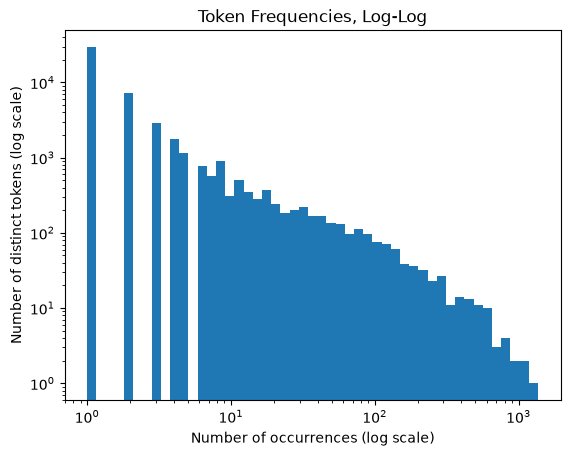

Share of tokens that appear exactly once: 0.6038898359039658
                   word  coefficient  magnitude  train_emails_containing
1504  background-image:    -0.891476   0.891476                       26
740           localized     0.815698   0.815698                       28
1406         helvetica,     0.717349   0.717349                       14
2362            thermal     0.706216   0.706216                       13
906               aging     0.622411   0.622411                       42
2566         transcript     0.578132   0.578132                       10
2559            april's    -0.546313   0.546313                       11
1494         retrieving    -0.527824   0.527824                       11
818                cnet    -0.510492   0.510492                       29
2657              zdnet    -0.503465   0.503465                        7
2532             xanaax     0.503086   0.503086                       14
1256             arial,    -0.485267   0.485267                

In [59]:
# Your Phase 2 solution to the problem goes here.
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

# suggestion 1: log-log histogram of token frequencies
with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
occurrences = pd.Series(Counter(all_tokens))
plt.hist(occurrences, bins=np.logspace(0, np.log10(occurrences.max()), 50))
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of occurrences (log scale)")
plt.ylabel("Number of distinct tokens (log scale)")
plt.title("Token Frequencies, Log-Log")
plt.show()
print("Share of tokens that appear exactly once:", (occurrences == 1).mean())

# suggestion 2: abs() for magnitude, and show how many training e-mails contain each top word
df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.loc[:, df.columns != "Email Type"]
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=100)

model = LinearRegression().fit(X_train, y_train)
coefficients = pd.DataFrame({
    "word": X_train.columns,
    "coefficient": model.coef_,
    "magnitude": np.abs(model.coef_),
    "train_emails_containing": X_train.sum().to_numpy(),
})
print(coefficients.sort_values("magnitude", ascending=False).head(15))

# suggestion 4: variance explained by the first two components
pca2 = PCA(n_components=2).fit(X)
print("Explained variance ratio (PC1, PC2):", pca2.explained_variance_ratio_)

# suggestion 6: vary the number of components, choosing L on a validation split of the training data.
# PCA is fit on the fitting subset only so the validation e-mails don't influence the components.
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=100)
pca_fit = PCA().fit(X_fit)
Z_fit = pca_fit.transform(X_fit)
Z_val = pca_fit.transform(X_val)

results = []
for L in [2, 10, 50, 100, 250, 500, 1000, 1500, 2000, 2610]:
    m = LinearRegression().fit(Z_fit[:, :L], y_fit)
    results.append((L, m.score(Z_fit[:, :L], y_fit), m.score(Z_val[:, :L], y_val)))
results = pd.DataFrame(results, columns=["L", "fit_R2", "validation_R2"])
print(results)

# after choosing L, refit PCA and the regression on all of X_train, then evaluate once on X_test
best_L = int(results.loc[results["validation_R2"].idxmax(), "L"])
pca = PCA().fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
final = LinearRegression().fit(Z_train[:, :best_L], y_train)
print("Chosen L:", best_L)
print("Train R^2:", final.score(Z_train[:, :best_L], y_train))
print("Test R^2:", final.score(Z_test[:, :best_L], y_test))


### Written answers (Phase 2)

**Q1 – Token frequencies.** On log-log axes the distribution is clearly heavy-tailed: 60% of the 48,691 distinct tokens appear exactly once, while a handful of tokens appear over 1,000 times. A few very common words and a long tail of rare ones is typical of text data.

**Q2.2 – R².** The training R² is 0.768 and the test R² is 0.659. The model has 2,711 features and about 14,900 training e-mails, so it fits some noise in the training set, which explains the gap. It still explains a substantial share of the variation on unseen e-mails.

**Q2.3 – Influential words.** The largest coefficients are "background-image:" (-0.89), "localized" (0.82), "helvetica," (0.72) and "thermal" (0.71). Positive coefficients push the prediction toward phishing and negative ones toward legitimate mail. These words should be interpreted with caution: most of them appear in only 7–45 training e-mails, so their coefficients are unstable. "helvetica," and "arial," are both font tokens but have opposite signs, which suggests they reflect the formatting of particular e-mail templates rather than something about scams.

**Q3 – PCA plot.** The first two components explain only about 1.1% and 0.9% of the variance, so the plot shows just a small part of the structure. Both classes overlap heavily, and the two components do not separate phishing from non-phishing e-mails.

**Q4 – PCA regression.** With 2,610 of 2,711 components, the regression uses almost the full rotation of the original data, which is why the R² values are nearly identical (train 0.767 vs 0.768, test 0.660 vs 0.659). Varying L showed that the validation R² is flat once L is above about 1,500. A validation split of the training data (with PCA fit only on the fitting subset) chose L = 2,000, which gave a test R² of 0.664, about 0.005 higher than the full model. That is a small improvement, not a big one.

**Q5 – Why use principal components.** The components are uncorrelated linear combinations of the tokens, ordered by how much variance they capture. This removes the redundancy between correlated tokens and makes it possible to drop the last components, which carry mostly noise. When I do that, the number of regression inputs falls and the test R² rises slightly. Keeping nearly all components, as in Q4, gives little benefit.


### *Reflection on AI assistance
In your own words without generative AI.


[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]


I think overall the AI was good at giving me suggestions and helping me understand the results better. Changing the histogram to log axes was a good suggestion since before it was mostly just one tall bar and it was hard to see anything else. Showing how many emails contained each of the words with large coefficients was also useful because I hadn't really considered that some of those words barely appeared in the training data. I do think though that some suggestions weren't necessary, such as standardizing all the token columns. Since the features were already 0/1, that would give rare words more weight so I ended up rejecting that one. I think the suggestion to try different numbers of principal components was useful since keeping 2,610 out of 2,711 components wasn't changing the model very much. The validation results picked 2,000 components although 1,500 was pretty close. I verified the changes by looking at the outputs and checking if they matched the written explanations and the decisions in my table. The final test R^2 was slightly higher but the difference was pretty small, so I don't think it shows that PCA is always going to make the predictions better.